# IoT-23 Scenario 1: feature selection → synthetic data → similarity

**The experiment in one picture**

```
real data ──split──► TRAIN (70%)                         TEST (30%, never touched until scoring)
                       │
        ┌──────────────┴───────────────┐
        │ 3 feature-ranking techniques │  (mutual information, ANOVA F-test, random-forest permutation importance)
        └──────────────┬───────────────┘
                       ▼
          voting → final top-N features
                       │
       ┌───────────────┴────────────────┐
       ▼                                ▼
 CTGAN on ALL features (baseline)   CTGAN on TOP-N features
       │                                │
       └───────► synthetic tables ◄─────┘
                       │
   compare each synthetic table with the REAL TEST table using
   (A) column-distribution similarity   (B) column-relationship similarity   (C) TSTR (bonus)
```

**Rule that keeps the experiment honest:** feature selection only ever sees the TRAIN split.

## 0. Setup and settings

In [ ]:
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from sklearn.feature_selection import mutual_info_classif, f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import f1_score

from sdv.metadata import Metadata
from sdv.single_table import CTGANSynthesizer
from sdmetrics.single_column import KSComplement, TVComplement
from sdmetrics.column_pairs import CorrelationSimilarity, ContingencySimilarity

warnings.filterwarnings("ignore")

DATA_PATH = "data/CTU-IoT-Malware-1-1.conn.log.labeled"
N_SELECT = 6          # how many features each technique votes for, and how many we finally keep
EPOCHS = 200          # CTGAN training epochs (more = better quality, slower)
SEEDS = [42]          # add more seeds, e.g. [42, 43, 44], to report mean +/- std

## 1. Load the Zeek log

The file is a Zeek `conn.log`: tab-separated, with `#`-prefixed header lines.
The column names are on the line that starts with `#fields`, so we read them from there.
In Zeek, `-` means "no value", so we turn it into `NaN`.

In [ ]:
with open(DATA_PATH) as f:
    for line in f:
        if line.startswith("#fields"):
            columns = line.rstrip("\n").split("\t")[1:]   # first item is the word '#fields'
            break

raw = pd.read_csv(DATA_PATH, sep="\t", comment="#", header=None, names=columns, na_values=["-", "(empty)"])
print(raw.shape)
raw.head()

(7008, 23)


,ts,uid,id.orig_h,id.orig_p,id.resp_h,id.resp_p,proto,service,duration,orig_bytes,...,local_resp,missed_bytes,history,orig_pkts,orig_ip_bytes,resp_pkts,resp_ip_bytes,tunnel_parents,label,detailed_label
0,1.525880e+09,CwxSC63ae0nsF5U8Rc,192.168.100.103,43763,154.8.94.65,14336,udp,NaN,NaN,NaN,...,NaN,0,D,1,40,0,0,NaN,Benign,NaN
1,1.525880e+09,CUmrqr4svHuSXJy5z7,192.168.100.103,51524,65.127.233.163,23,tcp,NaN,2.999051,0.0,...,NaN,0,S,3,180,0,0,NaN,Malicious,PartOfAHorizontalPortScan
2,1.525880e+09,CH98aB3s1kJeq6SFOc,192.168.100.103,56305,63.150.16.171,23,tcp,NaN,NaN,NaN,...,NaN,0,S,1,60,0,0,NaN,Malicious,PartOfAHorizontalPortScan
3,1.525880e+09,C3GBTkINvXNjVGtN5,192.168.100.103,41101,111.40.23.49,23,tcp,NaN,NaN,NaN,...,NaN,0,S,1,60,0,0,NaN,Malicious,PartOfAHorizontalPortScan
4,1.525880e+09,CC6vK11dpBdpp6Tp82,192.168.100.103,43763,196.170.198.141,11764,udp,NaN,NaN,NaN,...,NaN,0,D,1,40,0,0,NaN,Benign,NaN


## 2. Clean and choose the target

* **Target (`label`)**: `Benign` vs `Malicious`. This is what the feature-selection methods try to predict.
* **`detailed_label` is dropped** — it is just a finer version of the target (e.g. `PartOfAHorizontalPortScan`), so keeping it would leak the answer.
* **Dropped as identifiers / artifacts**: `ts` (capture time), `uid` (random flow id), `id.orig_h`, `id.resp_h` (IP addresses — identifiers, same decision as for the CIC data).
* **Dropped as constant**: columns with a single value carry no information.
* Missing numeric values (e.g. `duration` of a flow that never got a reply) become `0`, which is what "no data" means for these counters.

In [ ]:
df = raw.copy()
df = df.drop(columns=["ts", "uid", "id.orig_h", "id.resp_h", "detailed_label"])

# constant / all-empty columns tell us nothing
constant = [c for c in df.columns if df[c].nunique(dropna=True) <= 1]
print("dropping constant columns:", constant)
df = df.drop(columns=constant)

CATEGORICAL = [c for c in ["proto", "service", "conn_state", "history", "label"] if c in df.columns]
NUMERICAL = [c for c in df.columns if c not in CATEGORICAL]

df[NUMERICAL] = df[NUMERICAL].fillna(0)
df[CATEGORICAL] = df[CATEGORICAL].fillna("none").astype(str)

print("numerical  :", NUMERICAL)
print("categorical:", CATEGORICAL)
print()
print(df["label"].value_counts())
print("exact duplicate rows:", df.duplicated().sum(),
      "(kept: repeated scan flows are genuinely repeated in the real traffic)")

dropping constant columns: ['service', 'local_orig', 'local_resp', 'missed_bytes', 'tunnel_parents']
numerical  : ['id.orig_p', 'id.resp_p', 'duration', 'orig_bytes', 'resp_bytes', 'orig_pkts', 'orig_ip_bytes', 'resp_pkts', 'resp_ip_bytes']
categorical: ['proto', 'conn_state', 'history', 'label']

label
Malicious    4008
Benign       3000
Name: count, dtype: int64
exact duplicate rows: 1641 (kept: repeated scan flows are genuinely repeated in the real traffic)


## 3. Train / test split

70% train, 30% test, keeping the Benign/Malicious ratio the same in both (`stratify`).
**The test set is only used at the end, to score the synthetic data.**

In [ ]:
train, test = train_test_split(df, test_size=0.3, stratify=df["label"], random_state=42)
train = train.reset_index(drop=True); test = test.reset_index(drop=True)
FEATURES = [c for c in df.columns if c != "label"]
print("train", train.shape, "| test", test.shape, "| candidate features:", len(FEATURES))

train (4905, 13) | test (2103, 13) | candidate features: 12


## 4. Rank features with three techniques (TRAIN only)

| Technique | Question it answers | Caveat |
|---|---|---|
| **Mutual information** | How much does knowing this feature tell me about the label? Catches non-linear links. | Needs to know which features are discrete. |
| **ANOVA F-test** | Do the feature's *averages* differ between Benign and Malicious? | Only meaningful for **numeric** features, so categorical features get no ANOVA score. |
| **Permutation importance** (random forest) | Train a classifier, shuffle one feature, see how much accuracy drops. | Correlated features can hide each other. |

The models need numbers, so categorical features are turned into integer codes first (`OrdinalEncoder`) — only for this ranking step.

In [ ]:
X = train[FEATURES].copy()
y = train["label"]

# integer codes for the categorical features (ranking only; CTGAN gets the original text later)
cat_features = [c for c in FEATURES if c in CATEGORICAL]
num_features = [c for c in FEATURES if c in NUMERICAL]
X[cat_features] = OrdinalEncoder().fit_transform(X[cat_features])
is_discrete = [c in CATEGORICAL for c in FEATURES]

# --- technique 1: mutual information (all features) ---
mi = pd.Series(mutual_info_classif(X, y, discrete_features=is_discrete, random_state=42), index=FEATURES)

# --- technique 2: ANOVA F-test (numeric features only) ---
anova = pd.Series(f_classif(X[num_features], y)[0], index=num_features).reindex(FEATURES)  # NaN for categorical

# --- technique 3: random-forest permutation importance ---
# fit on part of train and measure the accuracy drop on the rest of train (test stays untouched)
X_fit, X_val, y_fit, y_val = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1).fit(X_fit, y_fit)
print("random forest accuracy on the validation part of train:", round(rf.score(X_val, y_val), 4))
perm = pd.Series(permutation_importance(rf, X_val, y_val, n_repeats=10, random_state=42, n_jobs=-1).importances_mean,
                 index=FEATURES)

scores = pd.DataFrame({"mutual_info": mi, "anova_f": anova, "perm_importance": perm})
scores.sort_values("mutual_info", ascending=False).round(4)

random forest accuracy on the validation part of train: 0.9967


,mutual_info,anova_f,perm_importance
id.resp_p,0.6713,4914.5004,0.2236
id.orig_p,0.5468,469.8490,0.0004
history,0.5162,NaN,0.0006
proto,0.5155,NaN,0.0003
orig_ip_bytes,0.5109,1230.2012,-0.0002
orig_pkts,0.0793,658.0660,0.0000
duration,0.0779,176.3757,0.0000
conn_state,0.0324,NaN,0.0000
resp_bytes,0.0140,77.2489,0.0000
resp_pkts,0.0094,14.3891,0.0000


## 5. Voting

Each technique looks at its own ranking and gives **one vote** to each of its top `N_SELECT` features.
Features are then sorted by number of votes; ties are broken by **average rank** (lower = better).
This is a rule we are *testing*, not a guarantee that the chosen subset is optimal.

In [ ]:
# 1 = best; NaN stays NaN (no ANOVA score for categoricals).
# method="first": tied scores (e.g. many features have permutation importance of exactly 0) are ranked one after
# another instead of all sharing a rank, so each technique hands out exactly N_SELECT votes.
ranks = scores.rank(ascending=False, method="first")
votes = (ranks <= N_SELECT).astype(int)

vote_table = votes.add_prefix("vote_").join(ranks.add_prefix("rank_"))
vote_table["votes"] = votes.sum(axis=1)
vote_table["avg_rank"] = ranks.mean(axis=1)                 # mean over the techniques that could score the feature
vote_table = vote_table.sort_values(["votes", "avg_rank"], ascending=[False, True])
vote_table["selected"] = [i < N_SELECT for i in range(len(vote_table))]

SELECTED = vote_table.index[:N_SELECT].tolist()
print("Selected features:", SELECTED)
vote_table

Selected features: ['id.resp_p', 'id.orig_p', 'history', 'proto', 'duration', 'orig_pkts']


,vote_mutual_info,vote_anova_f,vote_perm_importance,rank_mutual_info,rank_anova_f,rank_perm_importance,votes,avg_rank,selected
id.resp_p,1,1,1,1.0,1.0,1.0,3,1.000000,True
id.orig_p,1,1,1,2.0,4.0,3.0,3,3.000000,True
history,1,0,1,3.0,NaN,2.0,2,2.500000,True
proto,1,0,1,4.0,NaN,4.0,2,4.000000,True
duration,0,1,1,7.0,5.0,5.0,2,5.666667,True
orig_pkts,1,1,0,6.0,3.0,9.0,2,6.000000,True
orig_ip_bytes,1,1,0,5.0,2.0,12.0,2,6.333333,False
resp_bytes,0,1,0,9.0,6.0,7.0,1,7.333333,False
orig_bytes,0,0,1,11.0,7.0,6.0,1,8.000000,False
conn_state,0,0,0,8.0,NaN,8.0,0,8.000000,False


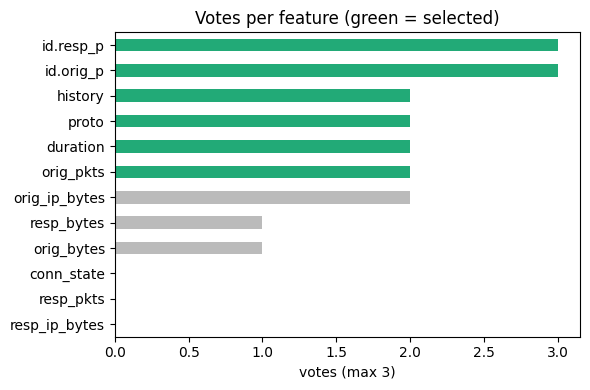

In [ ]:
# quick visual of the vote counts
vote_table["votes"].iloc[::-1].plot.barh(color=["#2a7" if s else "#bbb" for s in vote_table["selected"].iloc[::-1]],
                                          figsize=(6, 4), title="Votes per feature (green = selected)")
plt.xlabel("votes (max 3)"); plt.tight_layout(); plt.show()

## 6. Train CTGAN twice

* **Baseline**: all candidate features + `label`.
* **Selected**: only the voted features + `label`.

Same generator, same settings, same seed, so the *only* difference is the column set.
Each synthetic table has as many rows as the training table.

In [ ]:
def train_and_sample(cols, seed):
    """Fit CTGAN on train[cols], return (synthetic dataframe, training seconds)."""
    data = train[cols]
    # metadata tells SDV which columns are numbers and which are categories
    meta = Metadata.detect_from_dataframes({"flows": data})
    for c in cols:
        meta.update_column(column_name=c, table_name="flows",
                           sdtype="categorical" if c in CATEGORICAL else "numerical")
    torch.manual_seed(seed); np.random.seed(seed)
    synth = CTGANSynthesizer(meta, epochs=EPOCHS, batch_size=500, verbose=False)
    t0 = time.time()
    synth.fit({"flows": data})
    seconds = time.time() - t0
    return synth.sample(len(data))["flows"], seconds

experiments = {"baseline (all features)": FEATURES + ["label"],
               "selected (voted top-N)": SELECTED + ["label"]}
synthetic = {}   # (experiment, seed) -> dataframe
runtime = {}
for seed in SEEDS:
    for name, cols in experiments.items():
        synthetic[(name, seed)], runtime[(name, seed)] = train_and_sample(cols, seed)
        print(f"{name:26s} seed={seed}  columns={len(cols):2d}  {runtime[(name, seed)]:.0f}s")

baseline (all features)    seed=42  columns=13  118s


selected (voted top-N)     seed=42  columns= 7  84s


## 7. Compare synthetic vs real (against the held-out TEST table)

We never compare row 1 with row 1 — synthetic rows have no matching real row. We compare **distributions** and **relationships**.

**Method A — column distributions** (each column on its own), score 0–1, higher = more similar
* numeric columns → `KSComplement` = 1 − KS statistic (largest gap between the two cumulative distributions)
* categorical columns → `TVComplement` = 1 − total variation distance (gap between category proportions)

**Method B — relationships between columns**, score 0–1, higher = more similar
* numeric pairs → `CorrelationSimilarity` = 1 − |corr_real − corr_synth| / 2
* categorical pairs → `ContingencySimilarity` (compares the 2-way count tables)

**Method C (bonus) — TSTR**: train a classifier on the synthetic table, test it on real data (the protocol from your paper). It measures usefulness, not just resemblance.

To compare the two experiments **fairly, both are scored on the same columns** (the selected ones + label).
A score of 0.90 is a similarity score, not "90% accuracy". None of this measures privacy.

In [ ]:
def similarity(real, syn, cols):
    """Return average column-distribution and relationship similarity over `cols`."""
    num = [c for c in cols if c in NUMERICAL]
    cat = [c for c in cols if c in CATEGORICAL]

    # Method A: per-column scores
    per_col = {c: KSComplement.compute(real[c], syn[c]) for c in num}
    per_col.update({c: TVComplement.compute(real[c], syn[c]) for c in cat})

    # Method B: per-pair scores (pairs that are constant in either table give NaN and are skipped)
    pairs = []
    for i, a in enumerate(num):
        for b in num[i + 1:]:
            pairs.append(CorrelationSimilarity.compute(real[[a, b]], syn[[a, b]]))
    for i, a in enumerate(cat):
        for b in cat[i + 1:]:
            pairs.append(ContingencySimilarity.compute(real[[a, b]], syn[[a, b]]))

    return {"numerical_cols": np.mean([per_col[c] for c in num]),
            "categorical_cols": np.mean([per_col[c] for c in cat]),
            "relationships": np.nanmean(pairs)}, per_col

def tstr(syn, cols):
    """Train on synthetic, test on real test set; macro-F1."""
    feats = [c for c in cols if c != "label"]
    enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    cf = [c for c in feats if c in CATEGORICAL]
    Xs, Xt = syn[feats].copy(), test[feats].copy()
    if cf:
        Xs[cf] = enc.fit_transform(Xs[cf]); Xt[cf] = enc.transform(Xt[cf])
    clf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1).fit(Xs, syn["label"])
    return f1_score(test["label"], clf.predict(Xt), average="macro")

COMMON = SELECTED + ["label"]     # same columns for both experiments -> fair comparison
rows, per_column = [], {}
for (name, seed), syn in synthetic.items():
    s, pc = similarity(test, syn, COMMON)
    per_column[(name, seed)] = pc
    rows.append({"experiment": name, "seed": seed, "columns_trained_on": syn.shape[1],
                 **s, "TSTR_macroF1": tstr(syn, COMMON), "train_seconds": runtime[(name, seed)]})
results = pd.DataFrame(rows)
results

,experiment,seed,columns_trained_on,numerical_cols,categorical_cols,relationships,TSTR_macroF1,train_seconds
0,baseline (all features),42,13,0.758623,0.796148,0.863205,0.920536,117.673103
1,selected (voted top-N),42,7,0.759200,0.823622,0.876260,0.952267,84.398385


### Results table (mean over seeds; ± std appears only when you use more than one seed)

In [ ]:
summary = results.drop(columns="seed").groupby("experiment").agg(["mean", "std"]).round(3)
summary

columns_trained_on     numerical_cols      \
                                      mean std           mean std   
experiment                                                          
baseline (all features)               13.0 NaN          0.759 NaN   
selected (voted top-N)                 7.0 NaN          0.759 NaN   

                        categorical_cols     relationships     TSTR_macroF1  \
                                    mean std          mean std         mean   
experiment                                                                    
baseline (all features)            0.796 NaN         0.863 NaN        0.921   
selected (voted top-N)             0.824 NaN         0.876 NaN        0.952   

                            train_seconds      
                        std          mean std  
experiment                                     
baseline (all features) NaN       117.673 NaN  
selected (voted top-N)  NaN        84.398 NaN

In [ ]:
# reference points: real TRAIN vs real TEST (what 'perfect' looks like given sampling noise)
# and TSTR when training on real train data
ref, _ = similarity(test, train, COMMON)
print("real train vs real test similarity :", {k: round(v, 3) for k, v in ref.items()})
print("TSTR upper bound (train on REAL train):", round(tstr(train[COMMON], COMMON), 3))

real train vs real test similarity : {'numerical_cols': np.float64(0.979), 'categorical_cols': np.float64(0.994), 'relationships': np.float64(0.986)}


TSTR upper bound (train on REAL train): 0.999


## 8. Look at it, not just the numbers

Left: real test correlations; middle/right: synthetic correlations for each experiment (numeric selected columns).
Similar colors = relationships were preserved.

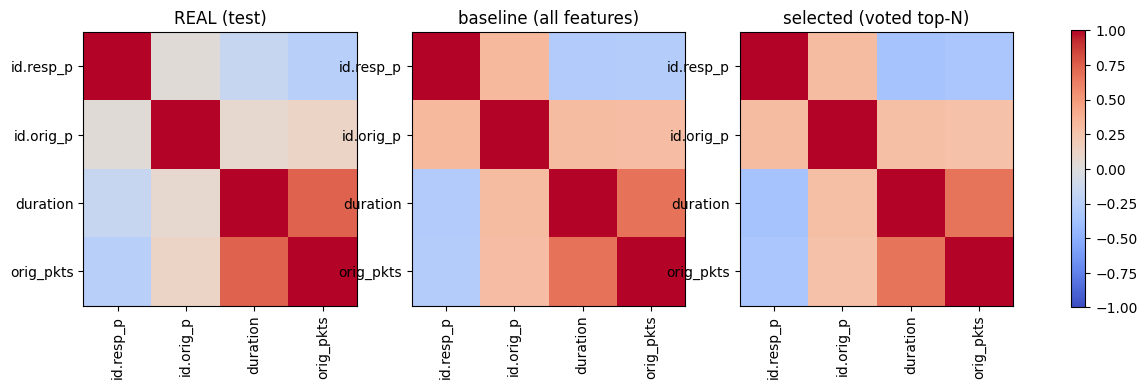

In [ ]:
num_common = [c for c in COMMON if c in NUMERICAL]
seed0 = SEEDS[0]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (title, frame) in zip(axes, [("REAL (test)", test)] +
                                     [(n, synthetic[(n, seed0)]) for n in experiments]):
    corr = frame[num_common].corr()
    im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
    ax.set_xticks(range(len(num_common))); ax.set_xticklabels(num_common, rotation=90)
    ax.set_yticks(range(len(num_common))); ax.set_yticklabels(num_common)
    ax.set_title(title)
fig.colorbar(im, ax=axes, shrink=0.8); plt.show()

In [ ]:
# per-column scores: which individual columns did each experiment reproduce well?
pd.DataFrame({name: per_column[(name, seed0)] for name in experiments}).round(3)

,baseline (all features),selected (voted top-N)
id.resp_p,0.733,0.751
id.orig_p,0.715,0.670
duration,0.590,0.643
orig_pkts,0.996,0.972
history,0.699,0.778
proto,0.842,0.837
label,0.847,0.855


## 9. Save outputs

Writes the ranking scores, the voting table, the synthetic tables and the comparison table to `results_iot23/`.

In [ ]:
import os
os.makedirs("results_iot23", exist_ok=True)
scores.to_csv("results_iot23/feature_scores.csv")
vote_table.to_csv("results_iot23/voting_table.csv")
results.to_csv("results_iot23/comparison.csv", index=False)
for (name, seed), syn in synthetic.items():
    syn.to_csv(f"results_iot23/synthetic_{name.split()[0]}_seed{seed}.csv", index=False)
print(os.listdir("results_iot23"))

['feature_scores.csv', 'voting_table.csv', 'synthetic_selected_seed42.csv', 'comparison.csv', 'synthetic_baseline_seed42.csv']


## How to read the results (and what NOT to conclude)

* If *selected* scores about the same as *baseline* on the same columns while training faster, feature selection kept what matters.
* `train_seconds` is wall-clock time on a shared laptop CPU, so it is a rough guide only (CTGAN time depends mostly on rows and epochs, not just column count).
* Differences of a few hundredths from a single seed can be noise — add seeds to `SEEDS` before claiming one is better.
* This dataset slice is small (~7k flows) and nearly all flows come from one device, so results may not carry over to other scenarios.
* Similarity scores measure **statistical fidelity** only — not privacy and not (except TSTR) usefulness.